# 18. Two ways to render the same frame

[Course plan](../../README.md)

Five colored splats sit on white. The upper-left corner is almost empty, yet the renderer from lesson 14 still evaluates all five splats at every pixel. A sideways camera move shifts the empty space as well. Which work can be skipped depends on the current view.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'en'


## 1. What belongs in a cell

Cutting the image into squares gives us *tiles*. Pale cells on the list map are nearly empty. Darker blue cells intersect more splats. Cells along the border can be shorter or narrower. Changing the tile size changes the number of pairs to test while preserving the pixels. Tightening a splat’s cutoff changes the image itself.


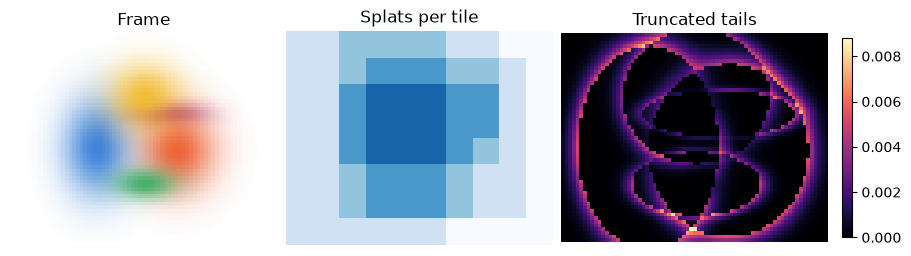

In [2]:
display(tiles_figure(lang=lang))
plt.close()
controls(lambda tile, k, angle: tiles_figure(int(tile), k, angle, lang),
         tile=[8, 4, 16, 32], k=(1., 4., .1, 3.), angle=(-45, 45, 1, 0))


## 2. Where a soft splat ends

Strictly speaking, it never does. On a bell centered at 9 with width 2, sample 13 is $(13-9)/2=2$ widths from the center. Squaring 2 gives 4. Dividing by −2 gives −2, and the exponential turns this into $e^{-2}\approx0.1353$. At three widths the weight is still positive, $e^{-9/2}\approx0.0111$. With opacity 0.8, alpha at that boundary is about $0.8\cdot0.0111\approx0.0089$.

An ellipse has two displacements. Suppose the projected center is $m=(9,6)$ and the horizontal and vertical widths are 2 and 1 pixels. At $p=(12,7)$ the offsets are 3 and 1 pixels. Squared distance in units of the splat’s own widths is

$$
q=(3/2)^2+(1/1)^2=2.25+1=3.25.
$$

With cutoff $k=2$, this passes the test $q\le k^2=4$. Its weight is $e^{-3.25/2}\approx0.197$. For a rotated ellipse, lesson 13 gives $q=(p-m)^T S^{-1}(p-m)$, with $S$ the screen covariance in squared pixels. Its inverse removes the units of scale. Both $q$ and $k$ are dimensionless. Both renderers set the weight to zero outside this boundary.


In [3]:
q = (3/2)**2 + (1/1)**2
print("q =", q, "weight =", np.exp(-q/2))
assert q < 2**2 and np.exp(-9/2) < .012


q = 3.25 weight = 0.19691167520419406


## 3. From an ellipse to a tile list

At two widths the same splat reaches from $9-2\cdot2=5$ to $9+2\cdot2=13$ horizontally and from $6-2\cdot1=4$ to 8 vertically. That rectangle encloses the ellipse. A corner sample can lie in the rectangle and still fail $q\le4$.

With 4-pixel tiles, columns 0–3 belong to tile 0 and columns 4–7 to tile 1. Integer division by 4 gives the tile index. Our rectangle reaches tiles 1, 2, 3 horizontally and 1, 2 vertically. One Gaussian gets $3\cdot2=6$ references. Its shape and color are stored once. For a rotated covariance the bounding half-width is $k\sqrt{S_{xx}}$, the half-height $k\sqrt{S_{yy}}$. These diagonals are variances along the **screen** axes. The square root brings the units back to pixels.

The depth test drops centers behind the near plane. At the edge of the screen, center position alone cannot reject a splat. A center at column −1 with a radius of 3 pixels still reaches column 2. Pixel 0 can receive color while the center lies outside the left boundary. The tile test therefore intersects the footprint rectangle with the image.

Each pixel now needs just one list. The nearest center comes first, then the next center in depth order. A splat receives weight $T\alpha$, where $T$ is the fraction of the ray still available. At $T=0.6$ and $\alpha=0.25$, the color weight is $0.15$ and $0.6(1-0.25)=0.45$ passes through. The order affects the color, so all tiles preserve the same depth ordering.


In [4]:
sc = small_scene()
cam = orbit(0, 73, 57)
slow, brute = finite_render(sc, cam, 73, 57, 8, 3, tiled=False)
fast, bins = finite_render(sc, cam, 73, 57, 8, 3, tiled=True)
print("pairs:", brute["pairs"], "→", bins["pairs"])
print("max |fast − slow|:", np.max(np.abs(fast-slow)))
assert np.allclose(fast, slow, atol=1e-12, rtol=0)


pairs: 20805 → 8688
max |fast − slow|: 0.0


## 4. Counting work and measuring time

With 73 × 57 pixels and five visible splats, the full loop considers 20,805 pixel–splat pairs. A cutoff makes some weights zero, but the distance test has already been paid for. At tile size 8 the lists leave 8,688 pairs to check. One extra candidate in a 64-pixel tile costs 64 tests. Smaller tiles save tests while larger tiles save list entries and setup. Python overhead and array sizes also affect elapsed time. The measurement first renders a warm-up frame, then takes the median of repeated wall-clock timings on this machine.


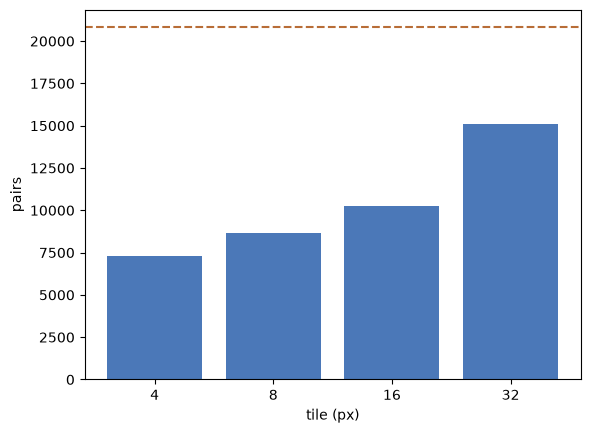

CPU ms: 4.0


In [5]:
sides = [4, 8, 16, 32]
counts = [finite_render(sc, cam, 73, 57, side)[1]["pairs"] for side in sides]
plt.bar([str(s) for s in sides], counts, color="#4b78b8")
plt.axhline(brute["pairs"], color="#b86d37", linestyle="--")
plt.ylabel("pairs"); plt.xlabel("tile (px)"); plt.show()
print("CPU ms:", round(benchmark(lambda: finite_render(sc, cam, 73, 57)), 2))


## 5. Where the original paper fits

Kerbl, Kopanas, Leimkühler, and Drettakis combine three mechanisms. Trainable 3D Gaussians hold shape and appearance. Density control adds or removes elements. The rasterizer turns the current model into an image quickly. The image loss from earlier lessons sends gradients back through rendering into the parameters. Our teaching implementation exposes the list traversal directly.

The authors’ implementation first culls centers, projects the covariance and computes a screen radius. Each splat–tile pair produces a record carrying a tile ID and depth. After sorting, neighboring records for a tile form one range. A GPU thread block processes a patch of the screen, loading candidate splats into shared memory in batches. Threads shade their pixels in parallel. The reference also includes screen filtering, a small-alpha threshold, an alpha cap and early termination when little transmittance remains. Equality between our arrays tests the two **teaching** paths with one common cutoff. The milliseconds above measure this CPU and this image size.

[Paper and results](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) · [Tile preparation and sorting](https://github.com/graphdeco-inria/diff-gaussian-rasterization/blob/main/cuda_rasterizer/rasterizer_impl.cu) · [Pixel processing on the GPU](https://github.com/graphdeco-inria/diff-gaussian-rasterization/blob/main/cuda_rasterizer/forward.cu)

## An experiment

What changes when tile size goes from 4 to 32 at the same cutoff? What if tile size stays at 4 but the splat stops at one width?

<details><summary>Worked answer</summary>

The first change alters the lists and test counts. Pixel weights and colors stay equal. The second removes samples whose weights were still around 0.6. Wider gaps show through. The difference from the full bell comes from its new support.

</details>
